# AI651 PA2 · Question 2 · Notebook 3 — Testing the baseline

Mirror and rotation tests (**Table 3, Figures 3–4** + GIFs) and faster motion
(**Table 4, Figure 5**). Uses the seed-0 model A for all figures.

**If the session disconnects:** reconnect (GPU runtime), then run the notebook again from the
top. Finished runs are loaded from Drive, an interrupted run continues from its last checkpoint
(end of every epoch and every 5 minutes inside an epoch), and cached metrics are not recomputed.

In [11]:
# 0) Drive, code and GPU -- run this first in every session
PROJECT = "/content/drive/MyDrive/AI651_PA2"   # data, checkpoints, results, figures live here
UPDATE_CODE = False   # True -> upload pa2_code.zip again (e.g. after you edit a script)

from google.colab import drive
drive.mount("/content/drive")

import os, sys, io, zipfile
CODE_DIR = os.path.join(PROJECT, "code")
os.makedirs(CODE_DIR, exist_ok=True)
if UPDATE_CODE or not os.path.exists(os.path.join(CODE_DIR, "pa2", "__init__.py")):
    from google.colab import files
    print("Upload pa2_code.zip (or the individual pa2/*.py files). "
          "It is stored on Drive, so this is only needed once.")
    for name, blob in files.upload().items():
        if name.endswith(".zip"):
            zipfile.ZipFile(io.BytesIO(blob)).extractall(CODE_DIR)
        elif name.endswith(".py"):
            os.makedirs(os.path.join(CODE_DIR, "pa2"), exist_ok=True)
            clean = name.split(" (")[0].removesuffix(".py") + ".py"   # Colab renames "x (1).py"
            with open(os.path.join(CODE_DIR, "pa2", clean), "wb") as f:
                f.write(blob)
assert os.path.exists(os.path.join(CODE_DIR, "pa2", "__init__.py")), "pa2 package not found on Drive"
if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)
for m in [m for m in list(sys.modules) if m == "pa2" or m.startswith("pa2.")]:
    del sys.modules[m]                         # always import the version on Drive

import numpy as np
import matplotlib.pyplot as plt
import pa2
from pa2 import config, data, models, train, evaluation, visuals, checks, tables, utils
from pa2.pipeline import Context
from pa2.utils import show_table
%matplotlib inline
print("pa2 version", pa2.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
pa2 version 1.0


In [12]:
Q2_5_COMMITTED = True   # set to True once your Q2.5 predictions are committed to GitHub
assert Q2_5_COMMITTED, "Commit your Q2.5 predictions before running these experiments."

In [13]:
ctx = Context(PROJECT)
ctx.load_data();   # first run: downloads Moving MNIST (~800 MB) to Drive; later runs load it from there

Device: Tesla T4 (15 GB), torch 2.11.0+cu130
Loading Moving MNIST (downloaded to Drive the first time) ...
{'train': (8000, 20, 1, 64, 64), 'val': (1000, 20, 1, 64, 64), 'test': (1000, 20, 1, 64, 64)}


In [14]:
SEL_PATH = os.path.join(ctx.paths["results"], "selection.json")
sel = utils.load_json(SEL_PATH, {})        # example videos chosen for the figures (reused later)

## Table 3 — consistency gaps and transformed errors (1×, t = 1)

In [15]:
show_table(tables.table3(ctx))

| Model | E(5) | C_M | E_M | C_R | E_R |
|---|---|---|---|---|---|
| A | 0.0222 (0.0225, 0.0219) | 0.00199 (0.00176, 0.00222) | 0.0228 (0.0231, 0.0226) | 0.00322 (0.00280, 0.00364) | 0.0239 (0.0240, 0.0238) |
| Blank | 0.0426 | 0 | 0.0426 | 0 | 0.0426 |
| Copy-last | 0.0641 | 0 | 0.0641 | 0 | 0.0641 |

Test split, 1×, t = 1, averaged over the five horizons.

## Figure 3 — videos with the largest per-video C_M and C_R (seed-0 model A)
Rows: (1) X | f(X), (2) T(X) | T(Y), (3) T(X) | f(T(X)), (4) T(X) | T(f(X)).
Each panel is also saved as a GIF stepping through the five horizons; the printed paths are
relative to the project folder, so copy `gifs/` into your repository as-is.

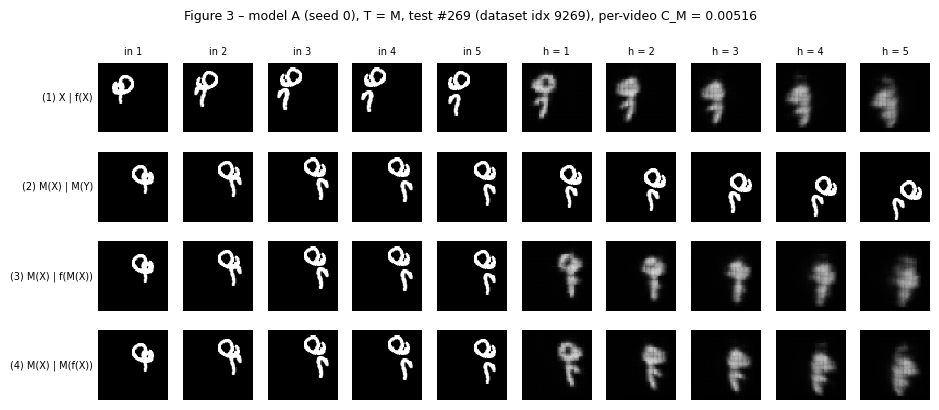

GIF: gifs/fig3_M_rank1_test269.gif


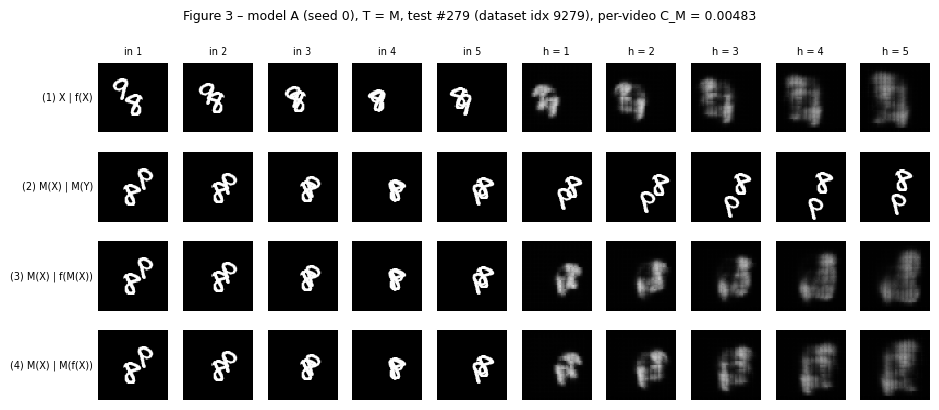

GIF: gifs/fig3_M_rank2_test279.gif


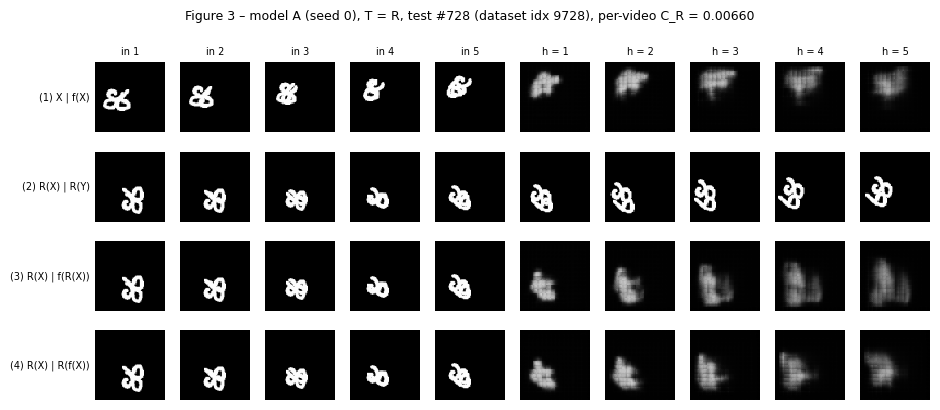

GIF: gifs/fig3_R_rank1_test728.gif


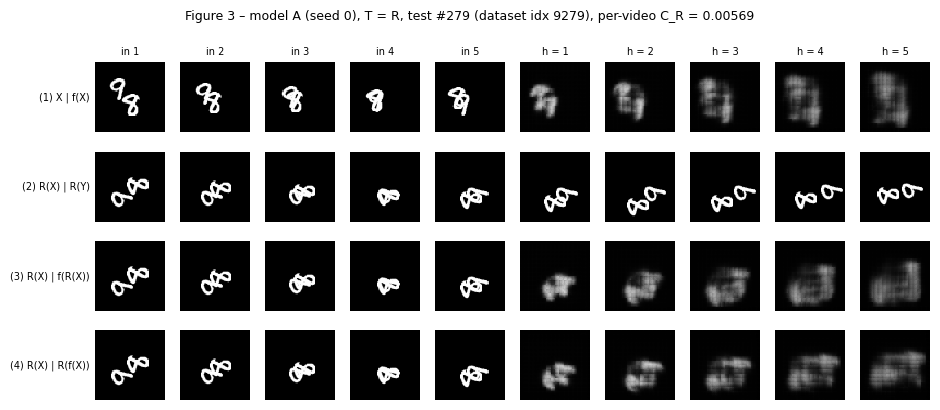

GIF: gifs/fig3_R_rank2_test279.gif


In [16]:
tr_A = ctx.metrics("A", 0, "tr")
sel["fig3"] = {"M": visuals.top_videos(tr_A["C_M"], 2), "R": visuals.top_videos(tr_A["C_R"], 2)}
utils.atomic_json_save(sel, SEL_PATH)
mA = ctx.model("A", 0)
for T in ("M", "R"):
    for rank, i in enumerate(sel["fig3"][T], 1):
        png = os.path.join(ctx.paths["figures"], f"fig3_{T}_rank{rank}_test{i}.png")
        gif = os.path.join(ctx.paths["gifs"], f"fig3_{T}_rank{rank}_test{i}.gif")
        visuals.figure_consistency_panel(
            mA, ctx.test, i, T, ctx.device, png, gif,
            f"Figure 3 – model A (seed 0), T = {T}, {visuals.vid_label(i)}, "
            f"per-video C_{T} = {utils.fmt(tr_A['C_' + T][i])}")
        plt.show()
        print("GIF:", os.path.relpath(gif, PROJECT))

## Figure 4 — per-video C_M and C_R over the test set (Figure 3 videos marked)

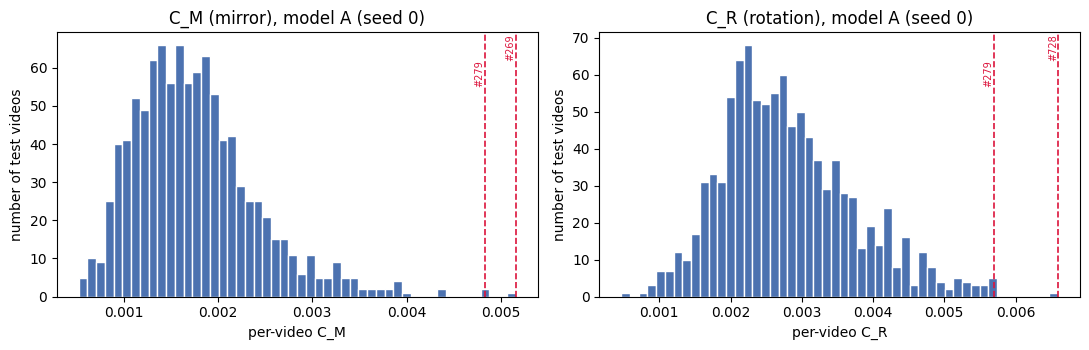

In [17]:
visuals.figure4(tr_A, sel["fig3"], os.path.join(ctx.paths["figures"], "fig4_consistency_hist.png"))
plt.show()

## Table 4 — faster motion (t = 1)

In [18]:
show_table(tables.table4(ctx))

| Model | E(2) 1× | E(2) 2× | E(2) 3× | E(5) 1× | E(5) 2× |
|---|---|---|---|---|---|
| A | 0.0188 (0.0190, 0.0185) | 0.0453 (0.0443, 0.0463) | 0.0530 (0.0524, 0.0536) | 0.0222 (0.0225, 0.0219) | 0.0506 (0.0482, 0.0531) |
| Copy-last | 0.0548 | 0.0661 | 0.0703 | 0.0641 | 0.0719 |

Test split, t = 1. Only E(2) is comparable across speeds.

## Figure 5 — one video at 1×, 2×, 3×
Chooses the first test video whose digits do not overlap in any displayed true frame.
Set `FIG5_ID` to pick another one (check the printed overlap counts are all zero).

test #21 (dataset idx 9021) | overlap per frame: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2]


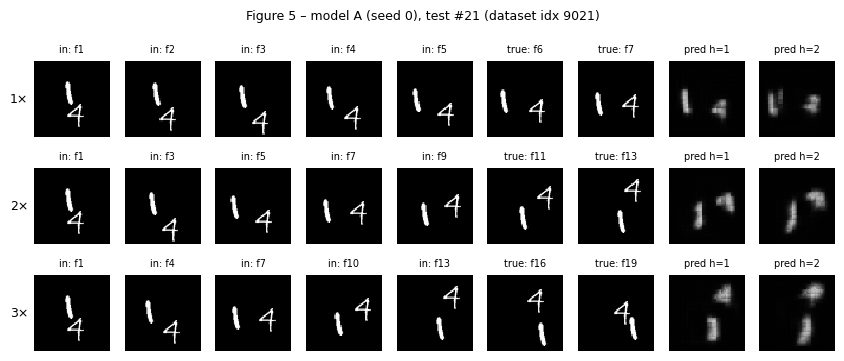

In [19]:
FIG5_ID = visuals.pick_fig5_video(ctx.test, tol=0)
if FIG5_ID is None:
    FIG5_ID = sel["fig5"] if "fig5" in sel else visuals.pick_fig5_video(ctx.test)
sel["fig5"] = int(FIG5_ID)
utils.atomic_json_save(sel, SEL_PATH)
print(visuals.vid_label(FIG5_ID), "| overlap per frame:", data.overlap_pixels(ctx.test[FIG5_ID]).astype(int))
visuals.figure_speeds(mA, ctx.test, FIG5_ID, ctx.device,
                      os.path.join(ctx.paths["figures"], "fig5_speeds_A.png"),
                      f"Figure 5 – model A (seed 0), {visuals.vid_label(FIG5_ID)}")
plt.show()

In [20]:
from google.colab import drive, files
import shutil
drive.mount("/content/drive")
P = "/content/drive/MyDrive/AI651_PA2"
out = "/content/repo_outputs"
shutil.rmtree(out, ignore_errors=True)
for d in ("figures", "gifs", "tables", "results"):
    shutil.copytree(f"{P}/{d}", f"{out}/{d}")
files.download(shutil.make_archive(out, "zip", out))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>